In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [2]:
graph_type = 'ER'
coup_type = 'ising'
d = 4

In [8]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/coal_time_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
df

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.22,F_beta_Glauber,False,full_star,25,10000000,100,25,2.206480e+03,7.842725e+02
1,0.22,F_beta_Glauber,False,full_star,25,10000000,500,25,2.276716e+04,6.898427e+03
2,0.22,F_beta_Glauber,False,full_star,25,10000000,1000,25,4.837880e+04,1.322644e+04
3,0.22,F_beta_Glauber,False,full_star,25,10000000,2500,25,1.647233e+05,4.040854e+04
4,0.22,F_beta_Glauber,False,full_star,25,10000000,5000,25,3.657235e+05,7.608673e+04
5,0.22,F_beta_Glauber,False,full_star,25,10000000,10000,25,8.776399e+05,2.040989e+05
6,0.22,F_beta_Glauber,False,full_star,25,10000000,25000,25,2.364027e+06,4.449193e+05
7,0.23,F_beta_Glauber,False,full_star,25,10000000,100,25,3.632240e+03,1.722701e+03
8,0.23,F_beta_Glauber,False,full_star,25,10000000,500,25,2.954560e+04,1.326566e+04
9,0.23,F_beta_Glauber,False,full_star,25,10000000,1000,25,7.870252e+04,4.629009e+04


# Scaling of coalescence times

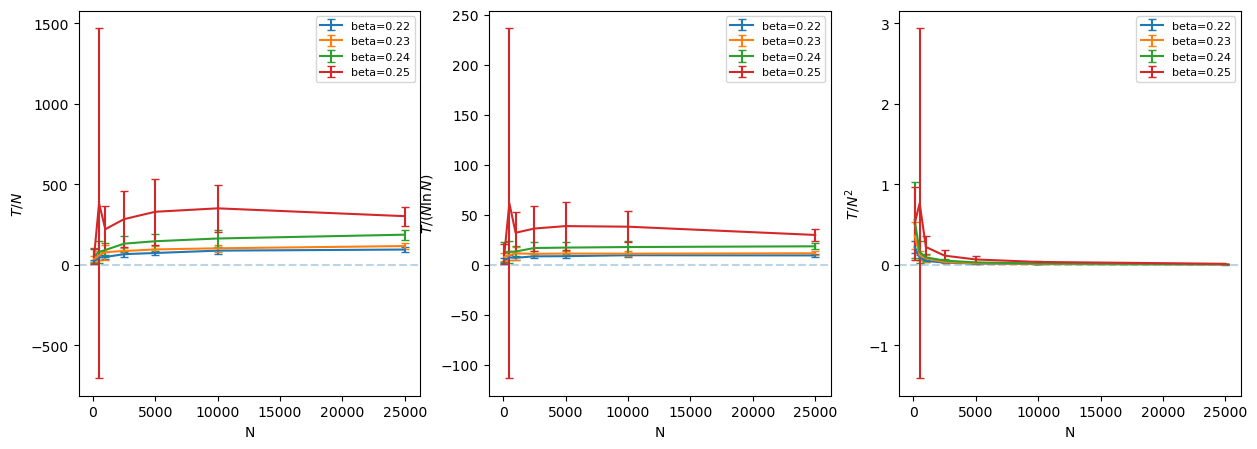

In [9]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
#    (df['n_coal'] == df['n_runs']) &
    (df['init_mode'] == 'full_star') 
)
df_filtered = df[mask]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

betas_to_exclude = [0.26, 0.27]
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        if beta in betas_to_exclude:
            continue    
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.show()

# Proba of coalescence

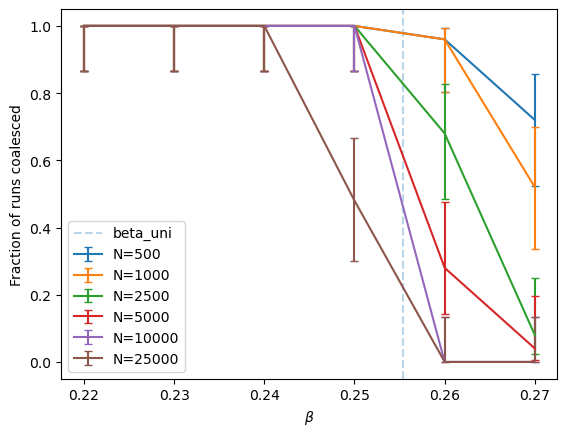

In [11]:
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') 
)
df_filtered = df[mask]

N_to_exclude = [100]
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.axvline(beta_uni, linestyle='--', alpha=0.3, label='beta_uni')
plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()